# 助詞で文を区切るやつ

2026/10/07-10

BCCWJ1 で句点「。」の直前に接続助詞がきている箇所の KWIC (`data/kwic-20337828.txt`) を読み込んで、どの接続助詞が多いか（レジスタ別に）見てみる。

## 0. データ読み込み

In [142]:
import csv

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["font.family"] = "Hiragino Sans"

kwic_path = "../data/kwic-20337828.txt"
df = pd.read_csv(kwic_path, sep="\t", quoting=csv.QUOTE_NONE, dtype=str)
print(len(df))
df[["前文脈", "キー", "後文脈", "出版年"]].head()

46017


,前文脈,キー,後文脈,出版年
0,の|だ|。#あからさま|な|実名|報道|、|いかに|も|いかがわしく|しつらえ|られ|た|印...,て,|(。)#それ|を|つくら|れ|た|“|像|”|で|ある|と|対象|化|する|読者|は|、|...,1986
1,だけ|で|“|殺さ|れ|て|も|仕方|が|ない|（|存在|）|”|と|きめつけ|て|いる|の|だ|,から,|(。)#許せ|ない|の|は|この|記事|の|末尾|に|ある|、|笹川|氏|の|恋人|と|の...,1986
2,斥ける|でしょう|。#お|化け|みたい|じゃ|なく|たって|いい|ん|だ|。#ぼく|は|お|...,から,|(。)# |文字|に|なれる|こと|は|、|誰|で|も|知っ|て|い|ます|。#仰向け|に...,1986
3,もちろん|物語|の|なか|の|青空|で|あり|、|わたし|は|それ|を|読ん|だ|に|すぎ|...,から,|(。)#と|すれ|ば|、|わたし|は|ここ|で|噓|を|つい|て|いる|の|です|が|、|...,1986
4,て|かんがえ|たい|。#ジェスチュア|と|いう|より|は|、|むしろ|ライフスタイル|と|い...,て,|(。)#身|の|ふり|かた|と|身|の|こなし|の|あいだ|に|、|はっきり|と|で|て|...,1986


In [143]:
def read_count(path, index_col):
    """中納言の件数を書き留めたファイルを、件数の Series にする"""
    df_count = pd.read_csv(path, sep="\t", quoting=csv.QUOTE_NONE, dtype=str)
    return df_count.set_index(index_col)["件数"].str.replace(",", "").str.strip().astype(int)


# 句点「。」の直前の語の品詞 (大分類) と、助詞の場合の中分類
count_hinshi = read_count("../data/bccwj1_maru-kuten_zempo1-hinshi.txt", "品詞の大分類")
count_joshi = read_count("../data/bccwj1_maru-kuten_zempo1-joshi.txt", "品詞の中分類")
count_joshi.index = count_joshi.index.str.replace("助詞-", "")

count_kuten_total = 4_018_225

# 合計が合うか確かめる: 品詞の合計 = 句点の件数 (4,018,225)、助詞の中分類の合計 = 助詞、接続助詞 = KWIC の行数
print(f"品詞の合計 {count_hinshi.sum():,} / 句点 {count_kuten_total:,}")
print(f"助詞 {count_hinshi['助詞']:,} / 中分類の合計 {count_joshi.sum():,}")
print(f"接続助詞 {count_joshi['接続助詞']:,} / KWIC {len(df):,}")

品詞の合計 4,015,256 / 句点 4,018,225
助詞 417,994 / 中分類の合計 417,994
接続助詞 46,017 / KWIC 46,017


## 1. 句点「。」の直前の接続助詞 内訳

In [144]:
count_key = df["キー"].value_counts()
count_key.head(10)

キー
から     11622
が      10413
て       9884
けど      5156
し       5130
ば        949
で        729
けれど      608
ながら      421
と        376
Name: count, dtype: int64

In [246]:
count_key = df["語彙素"].value_counts()
count_key.head(10)

語彙素
から     11628
て      10921
が      10419
けれど     5787
し       5141
ば        949
ながら      421
と        376
とも       114
に        103
Name: count, dtype: int64

In [245]:
# 語彙素が「て」の行を、表記 (キー) 別に数える。「て」と数えた 9,884 件は表記が「て」のものだけ
df_lemma_te = df[df["語彙素"] == "て"]
print(len(df_lemma_te))
display(df_lemma_te["キー"].value_counts().head(5))

# 表記が「で」のもの (〜ないで、読んで、等) の直前の語
df_de = df_lemma_te[df_lemma_te["キー"] == "で"]
prev_de = df_de["前文脈"].str.rstrip("|").str.split("|").str[-1].str.split("#").str[-1]
print(len(df_de))
prev_de.value_counts().head(10)

10921


キー
て      9884
で       729
ちゃ      264
ちゃあ      25
てぇ        7
Name: count, dtype: int64

729


前文脈
ない     457
選ん      44
楽しん     35
飲ん      17
読ん      14
喜ん      12
呼ん      10
頼ん       6
のぞん      5
進ん       5
Name: count, dtype: int64

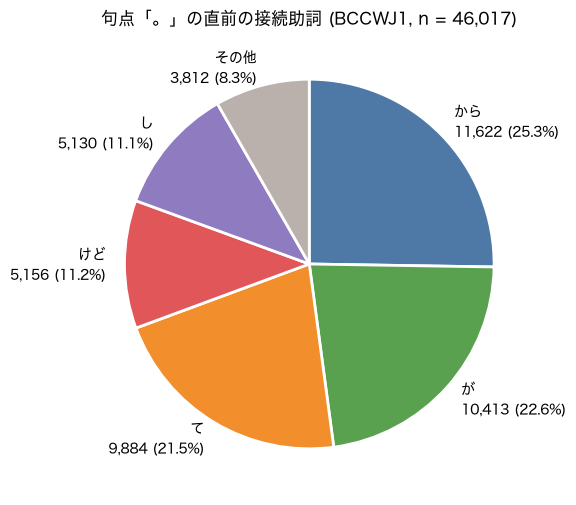

In [145]:
# 上位だけ残して、あとは「その他」にまとめる
top_n = 5
count_pie = count_key.head(top_n).copy()
count_pie["その他"] = count_key.iloc[top_n:].sum()

total = count_pie.sum()
labels = [f"{key}\n{count:,} ({count / total:.1%})" for key, count in count_pie.items()]
colors = ["#4e79a7", "#59a14f", "#f28e2b", "#e15759", "#8f7cc0", "#bab0ac"]


fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    count_pie,
    labels=labels,
    colors=colors,
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
)
ax.set_title(f"句点「。」の直前の接続助詞 (BCCWJ1, n = {total:,})")
#plt.savefig("figs/20261007_te.png")
plt.show()

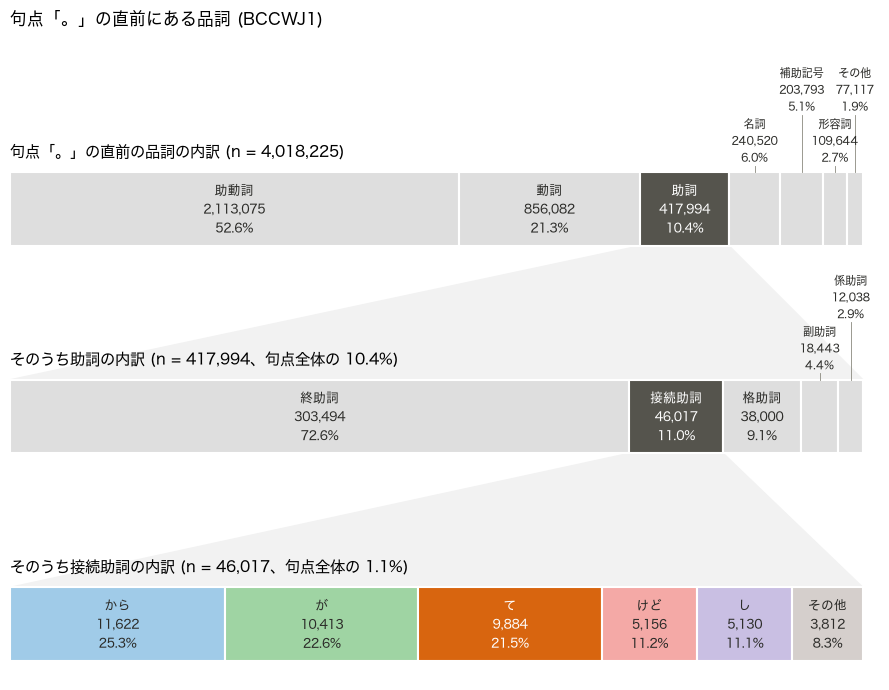

In [230]:
# 帯グラフを 3 段にして、上の段の一部を下の段で拡大していく
from matplotlib.colors import to_rgb

INK = "#2b2b28"
colors_hl = ["#a0cbe8", "#9fd4a3", "#d8650f", "#f4a9a6", "#c9bfe3", "#d5cfcc"]

def fold_small(count, min_share=0.02):
    """割合の小さい項目を「その他」にまとめて、多い順に並べる"""
    count = count.sort_values(ascending=False)
    small = count / count.sum() < min_share
    folded = count[~small].copy()
    if small.any():
        folded["その他"] = count[small].sum()
    return folded


def draw_band(ax, y, count, title, focus=None, band_colors=None, whole=None, height=0.46):
    """100% の帯を 1 本描く。focus の項目の左端と右端 (%) を返す

    focus の項目は濃い塗りに白い文字、ほかは薄い塗りに黒い文字にする
    whole を渡すと、この帯の合計が whole の何 % かをタイトルに添える
    """
    share = count / count.sum() * 100
    left = 0.0
    focus_range = None
    n_narrow = 0
    top = y + height / 2
    note = f"n = {count.sum():,}"
    if whole is not None:
        note += f"、句点全体の {count.sum() / whole:.1%}"
    ax.text(0, top + 0.08, f"{title} ({note})", fontsize=11, va="bottom")
    for i, (name, value) in enumerate(share.items()):
        if band_colors is not None:
            color = band_colors[i]
        else:
            color = "#55544d" if name == focus else "#dedede"
        text_color = "white" if name == focus else INK
        ax.barh(y, value, left=left, height=height, color=color, edgecolor="white", linewidth=1.5)
        center = left + value / 2
        label = f"{name}\n{count[name]:,}\n{value:.1f}%"
        if value >= 6.5:
            ax.text(center, y, label, ha="center", va="center", fontsize=9, color=text_color)
        elif value >= 0.5:
            # 幅の狭い項目は帯の上に、重ならないよう高さを交互に変えて書く
            lift = 0.04 + 0.32 * (n_narrow % 2)
            ax.plot([center, center], [top, top + lift], color="#8a897f", linewidth=0.6)
            ax.text(center, top + lift, label, ha="center", va="bottom", fontsize=8, color=INK)
            n_narrow += 1
        if name == focus:
            focus_range = (left, left + value)
        left += value
    return focus_range


def draw_zoom(ax, y_upper, y_lower, focus_range, height=0.46):
    """上の段の focus の範囲から、下の段の全体へ広がる帯を描く"""
    x0, x1 = focus_range
    top, bottom = y_upper - height / 2, y_lower + height / 2
    ax.fill([x0, x1, 100, 0], [top, top, bottom, bottom], color="#f2f2f2", zorder=0)


# 品詞の合計が句点の件数に足りない分は「不明」として足す (「その他」に入る)
count_hinshi_all = count_hinshi.copy()
count_hinshi_all["不明"] = count_kuten_total - count_hinshi.sum()

y_hinshi, y_joshi, y_setsuzoku = 2.6, 1.3, 0
fig, ax = plt.subplots(figsize=(9, 7))
range_joshi = draw_band(ax, y_hinshi, fold_small(count_hinshi_all), "句点「。」の直前の品詞の内訳", focus="助詞")
range_setsuzoku = draw_band(ax, y_joshi, fold_small(count_joshi), "そのうち助詞の内訳", focus="接続助詞", whole=count_kuten_total)
draw_band(ax, y_setsuzoku, count_pie, "そのうち接続助詞の内訳", focus="て", band_colors=colors_hl, whole=count_kuten_total)
draw_zoom(ax, y_hinshi, y_joshi, range_joshi)
draw_zoom(ax, y_joshi, y_setsuzoku, range_setsuzoku)

ax.set_xlim(0, 102)
ax.set_ylim(-0.35, 3.7)
ax.axis("off")
ax.set_title("句点「。」の直前にある品詞 (BCCWJ1)", loc="left")
fig.tight_layout()
plt.savefig("figs/20261007_te_band.png")
plt.show()

## 2. レジスターごとの割合（分母は句点「。」）

分母はレジスターごとの句点「。」の件数 (`data/bccwj1_maru-kuten_register.txt`)

In [147]:
kuten_path = "../data/bccwj1_maru-kuten_register.txt"
df_kuten = pd.read_csv(kuten_path, sep="\t", dtype=str)
count_kuten = (
    df_kuten.set_index("レジスター")["件数"].str.replace(",", "").str.strip().astype(int)
)

# 合計が全体の句点の件数 (4,018,225) と合うか確かめる
print(f"{count_kuten.sum():,}")
count_kuten

4,018,225


レジスター
出版・新聞            54459
出版・雑誌           184503
出版・書籍          1069047
図書館・書籍         1258202
特定目的・白書          97169
特定目的・ベストセラー     167140
特定目的・知恵袋        495218
特定目的・ブログ        418026
特定目的・法律          23026
特定目的・国会会議録      116686
特定目的・広報紙         93175
特定目的・教科書         40212
特定目的・韻文           1362
Name: 件数, dtype: int64

In [148]:
top_keys = list(count_key.head(top_n).index)
key_grouped = df["キー"].where(df["キー"].isin(top_keys), "その他")
count_register = pd.crosstab(df["レジスター"], key_grouped)[top_keys + ["その他"]]
count_register = count_register.reindex(count_kuten.index, fill_value=0)
count_register["計"] = count_register.sum(axis=1)

# 句点で終わる文のうち、接続助詞で終わっているものの割合 (%)
print("句点で終わる文のうち、接続助詞で終わっている割合 (%)")
rate_register = count_register.div(count_kuten, axis=0) * 100
rate_register["句点"] = count_kuten
rate_register.sort_values("計", ascending=False).round(2)

句点で終わる文のうち、接続助詞で終わっている割合 (%)


キー,から,が,て,けど,し,その他,計,句点
レジスター,,,,,,,,
特定目的・知恵袋,0.54,1.05,0.26,0.34,0.44,0.07,2.69,495218
特定目的・ブログ,0.29,0.49,0.46,0.40,0.37,0.18,2.19,418026
特定目的・韻文,0.29,0.15,0.81,0.00,0.00,0.44,1.69,1362
出版・雑誌,0.29,0.09,0.60,0.10,0.10,0.09,1.27,184503
特定目的・国会会議録,0.36,0.21,0.17,0.00,0.01,0.18,0.93,116686
特定目的・ベストセラー,0.31,0.10,0.20,0.06,0.05,0.10,0.83,167140
図書館・書籍,0.28,0.12,0.21,0.07,0.05,0.09,0.81,1258202
出版・書籍,0.25,0.10,0.22,0.06,0.05,0.09,0.76,1069047
特定目的・教科書,0.06,0.01,0.17,0.01,0.00,0.04,0.29,40212


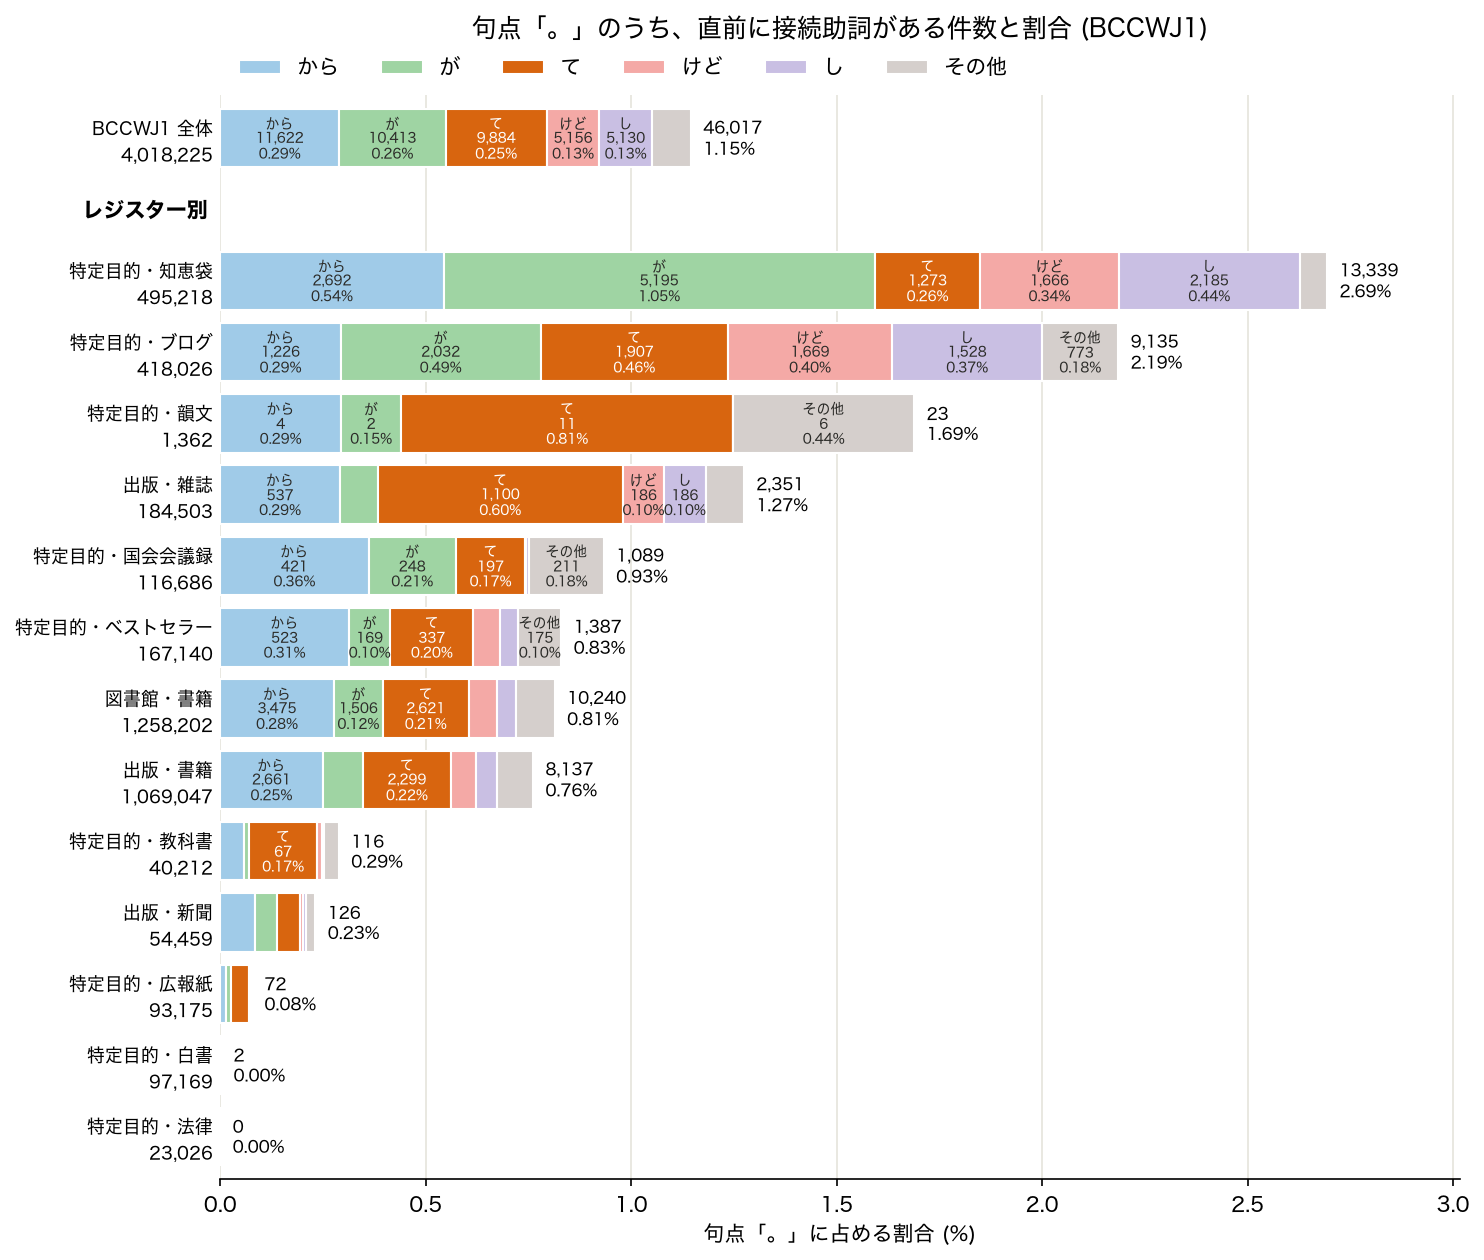

In [243]:
# 横棒の長さ = 直前に接続助詞がある割合の計、色分け = どの接続助詞か
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch


def text_color_on(color):
    """塗りの上で読みやすいほうの文字色 (白か黒) を返す"""
    r, g, b = [c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4 for c in to_rgb(color)]
    luminance = 0.2126 * r + 0.7152 * g + 0.0722 * b
    return "white" if luminance < 0.3 else "#2b2b28"


def draw_register_chart(te_rest=None, save_path="figs/20261007_te_register.png"):
    """レジスター別の帯グラフを描く

    te_rest (レジスター → 「て」のうち残る割合) を渡すと、「て」の帯のうち除外する分を薄くして、
    帯の中の件数と割合も残る分の目安にする
    """
    keys_plot = top_keys + ["その他"]
    rate_plot = rate_register.sort_values("計")[keys_plot]
    count_plot = count_register.loc[rate_plot.index, keys_plot]
    kuten_plot = count_kuten[rate_plot.index]

    # いちばん上に BCCWJ1 全体を足す (帯グラフの「句点全体の 1.1%」と同じ数字)
    count_plot.loc["BCCWJ1 全体"] = count_plot.sum()
    kuten_plot["BCCWJ1 全体"] = kuten_plot.sum()
    rate_plot.loc["BCCWJ1 全体"] = count_plot.loc["BCCWJ1 全体"] / kuten_plot["BCCWJ1 全体"] * 100

    # レジスターは下から 0, 1, 2, ...、1 行あけて (小見出し「レジスター別」を置く)、いちばん上に全体
    n_register = len(rate_plot) - 1
    y = list(range(n_register)) + [n_register + 1]
    min_width = 0.1  # これより幅の狭い帯には文字を入れない

    fig, ax = plt.subplots(figsize=(10, 8.5), dpi=150)
    left = pd.Series(0.0, index=rate_plot.index)
    for key, color in zip(keys_plot, colors_hl):
        ax.barh(y, rate_plot[key], left=left, height=0.82, color=color, edgecolor="white", linewidth=1, label=key)
        for y_bar, register in zip(y, rate_plot.index):
            rate = rate_plot.loc[register, key]
            count = count_plot.loc[register, key]
            if key == "て" and te_rest is not None:
                # 除外する分 (帯の右側) に白を重ねて薄くする
                rest = te_rest.get(register, 1.0)
                ax.barh(y_bar, rate * (1 - rest), left=left[register] + rate * rest, height=0.82,
                        color="white", alpha=0.65, linewidth=0)
                rate, count = rate * rest, round(count * rest)
            if rate >= min_width:
                label = f"{key}\n{count:,}\n{rate:.2f}%"
                ax.text(left[register] + rate / 2, y_bar, label, ha="center", va="center",
                        fontsize=6.5, linespacing=1.1, color=text_color_on(color))
        left += rate_plot[key]
    # 棒の右に、直前に接続助詞がある句点の件数と割合 (計)
    for y_bar, register in zip(y, rate_plot.index):
        total_text = f"{count_plot.loc[register].sum():,}\n{left[register]:.2f}%"
        ax.text(left[register] + 0.03, y_bar, total_text, va="center", fontsize=8, linespacing=1.2)

    # レジスター名の下に、分母になる句点の件数
    ax.set_yticks(y, [f"{register}\n{kuten_plot[register]:,}" for register in rate_plot.index], fontsize=8.5)
    ax.text(-0.01, n_register, "レジスター別", transform=ax.get_yaxis_transform(), ha="right", va="center", fontweight="bold")
    ax.set_xlim(0, left.max() * 1.12)
    ax.set_ylim(-0.6, n_register + 1.6)
    ax.set_xlabel("句点「。」に占める割合 (%)")
    ax.set_title("句点「。」のうち、直前に接続助詞がある件数と割合 (BCCWJ1)", pad=28)
    handles, _ = ax.get_legend_handles_labels()
    if te_rest is not None:
        color_te = to_rgb(colors_hl[keys_plot.index("て")])
        color_light = tuple(c + (1 - c) * 0.65 for c in color_te)
        handles.append(Patch(facecolor=color_light, label="「て」のうち除外する分 (概算)"))
    ax.legend(handles=handles, ncols=7, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False)
    ax.grid(axis="x", color="#e5e4dc", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
    fig.tight_layout()
    plt.savefig(save_path, dpi=200)
    plt.show()


draw_register_chart()

✏️メモ

- 句点で終わる文のうち、直前に接続助詞がある割合
    - 高いのは、知恵袋・ブログ・韻文・雑誌
    - 低い（ない）のは、法律・白書・広報紙・新聞
- 接続助詞別
    - `から`: 「知恵袋」で多く (0.54%)、  
    国会会議録・ベストセラー・ブログ・韻文・雑誌・書籍 (0.25-0.36%) でも多い
    - `が`: 知恵袋 (1.05%) ・ブログ (0.49%) で多い
    - `て`: 雑誌 (0.60%)、ブログ (0.46%) で多い
        - 韻文 (0.81%) でも多いが事例数としては少ない (11件)

韻文の 23 件（接続助詞）は、詩。

> ものを見守る視線の作るいくつかの交点を通るとき風はちょっと燃焼する、つぎつぎと軽い音を立て	て	(。)ガットに当るボールのふしぎな音のように。  
*OV2X_00005 衣更着信詩集	衣更着信	思潮社	1987*

雑誌にはアドバイスやインタビュー書き起こしがある。

アドバイス（依頼表現）
> シンプルな分、野菜の下ごしらえで味が決まるんです。今まで手を抜いていた野菜の下ごしらえを、少しだけていねいにしてみ	て	(。)「サラダがいつもと違う」と感じるはずです。  
*PM21_00369	相沢　ひろみ(著)/逆瀬川　由夏(著)	女性セブン		小学館	2002*

インタビュー（前節の理由を追加で述べる）
> 那和　僕もペンタックスＳＰ買ったのは、ニコンＦが買えなかったからですよ、当時お金がなく	て	(。)萩谷　私はこのリストの中では、ミノルタオートコードがいいなと思いますね。  
*PM11_00234	アサヒカメラ編集部(著)/河田　一規(著)/竹中　隆義(著)/萩谷　剛(著)/赤城　耕一(著)/那和　秀峻(著)	アサヒカメラ		朝日新聞社	2001*

## 3. 「て」の直前の語

`前文脈` は `|` で語に区切られているので、最後の語を取り出して数える

In [ ]:
df_te = df[df["キー"] == "て"].copy()
# 文頭の語には文境界の印がついている (「。#頑張っ」など) ので、# より前は落とす
df_te["直前の語"] = df_te["前文脈"].str.rstrip("|").str.split("|").str[-1].str.split("#").str[-1]
count_prev = df_te["直前の語"].value_counts()
print(len(df_te), len(count_prev))
count_prev.head(10)

In [151]:
# 上位の語をレジスター別に数える
top_prev = list(count_prev.head(15).index)
count_prev_register = pd.crosstab(df_te["直前の語"], df_te["レジスター"]).loc[top_prev]
count_prev_register["計"] = count_prev_register.sum(axis=1)
count_prev_register

レジスター,出版・新聞,出版・書籍,出版・雑誌,図書館・書籍,特定目的・ブログ,特定目的・ベストセラー,特定目的・国会会議録,特定目的・広報紙,特定目的・教科書,特定目的・白書,特定目的・知恵袋,特定目的・韻文,計
直前の語,,,,,,,,,,,,,
し,2,316,170,361,278,57,44,7,11,0,186,1,1433
まし,1,66,25,81,171,13,19,0,1,0,105,0,482
なく,2,100,21,112,81,7,6,0,1,0,109,0,439
つい,6,65,15,74,49,3,28,17,0,1,121,0,379
み,0,58,75,43,50,4,0,0,1,0,63,0,294
思っ,1,57,32,77,52,15,0,0,1,0,39,0,274
ちゃっ,0,65,18,88,51,6,0,0,1,0,16,0,245
い,0,70,8,43,59,4,1,0,0,0,23,0,208
なっ,1,51,16,63,34,5,3,0,7,0,19,1,200


### 3.1. 「いて。」

In [152]:
def show_examples(prev, n=30, register=None, seed=0):
    """「prev + て。」の例を n 件、ランダムに取り出して表示する"""
    rows = df_te[df_te["直前の語"] == prev]
    if register is not None:
        rows = rows[rows["レジスター"] == register]
    print(f"{prev}て。 {len(rows)} 件")
    for _, row in rows.sample(min(n, len(rows)), random_state=seed).iterrows():
        context = row["前文脈"].replace("|", "")[-40:]
        print(f"{row['レジスター']}\t{context}【て】。")


show_examples("い")

いて。 208 件
図書館・書籍	いかなかった。#　みんなは私の知らない何かについて喋り続けてい【て】。
特定目的・ブログ	が設立されたと記述あり。#さらに、広報も活動の一環と捉えてい【て】。
図書館・書籍	いたから、つらいこと、悲しいことをいやっていうほど経験してきてい【て】。
図書館・書籍	病気や。#春までには、ちゃんとようなってみせるさけ、心配せんとい【て】。
出版・書籍	の声。#迅雷の背後に、桓魋たちの仲間。#桓魋ではなく柴望がい【て】。
特定目的・ブログ	いる。#そんなチヒョンに、#「いいから。#いいから。#ゲストは居間でくつろいでい【て】。
特定目的・ブログ	ても自分の命を犠牲にしても解決するからどうか安心してい【て】。
特定目的・ブログ	ために国際的なところでまっとうな貢献をするからどうか　安心してい【て】。
特定目的・ブログ	ために国際的なところでまっとうな貢献をするからどうか　安心してい【て】。
出版・書籍	。#一生懸命明るく振る舞っている、郷子。#将一と優は、淡々としてい【て】。
特定目的・ベストセラー	大切にしてあげよう。#愛ちん、もっとオレ、大人になるからずっと一緒にい【て】。
出版・書籍	」#「いやよ。#ね、話は応接間ですむから、このまま寝てい【て】。
特定目的・知恵袋	３チャンネル見れます。#画面の説明の端には「契約済み」と出てい【て】。
出版・書籍	■陽子の私室#向き合って会話する陽子と遠甫。#嬉しくお茶を出す玉葉がい【て】。
特定目的・ブログ	ために国際的なところでまっとうな貢献をするからどうか　安心してい【て】。
特定目的・ブログ	んですよね〜。#そしたら、彼氏後輩がなんだかしんみりしてい【て】。
出版・雑誌	ね。#そこら中に女口説いてる奴や、振られて泣いてる奴がい【て】。
図書館・書籍	見つめていた。#　稲葉にいった―もう消えないで、ずっとそばにい【て】。
特定目的・知恵袋	友達と一緒に始めます。#友達はずっと経験があるから、お客様はい【て】。
図書館・書籍	子の髪、こんなに伸びましたのよ。#それも、ゆっさりしてい【て】。
出版・書籍	ございます…でも、悪くないさ、恵達」#ステージ袖には、祥子がい【て】。
図書館・書籍	初夜」は日没後三、四時間の間。#十一　長い間倒れてい【て】。
図書館・書籍	だめよ、冬城、無理だわ。#あなたは『

<!--
```
図書館・書籍	いかなかった。#　みんなは私の知らない何かについて喋り続けてい【て】。	o
特定目的・ブログ	が設立されたと記述あり。#さらに、広報も活動の一環と捉えてい【て】。	o
図書館・書籍	いたから、つらいこと、悲しいことをいやっていうほど経験してきてい【て】。	o
図書館・書籍	病気や。#春までには、ちゃんとようなってみせるさけ、心配せんとい【て】。	x (依頼)
出版・書籍	の声。#迅雷の背後に、桓魋たちの仲間。#桓魋ではなく柴望がい【て】。	o
特定目的・ブログ	いる。#そんなチヒョンに、#「いいから。#いいから。#ゲストは居間でくつろいでい【て】。	o
特定目的・ブログ	ても自分の命を犠牲にしても解決するからどうか安心してい【て】。	x (依頼)
特定目的・ブログ	ために国際的なところでまっとうな貢献をするからどうか　安心してい【て】。	x (依頼)
特定目的・ブログ	ために国際的なところでまっとうな貢献をするからどうか　安心してい【て】。	x (依頼)
出版・書籍	。#一生懸命明るく振る舞っている、郷子。#将一と優は、淡々としてい【て】。	o
特定目的・ベストセラー	大切にしてあげよう。#愛ちん、もっとオレ、大人になるからずっと一緒にい【て】。	x (依頼)
出版・書籍	」#「いやよ。#ね、話は応接間ですむから、このまま寝てい【て】。	x (依頼)
特定目的・知恵袋	３チャンネル見れます。#画面の説明の端には「契約済み」と出てい【て】。	o
出版・書籍	■陽子の私室#向き合って会話する陽子と遠甫。#嬉しくお茶を出す玉葉がい【て】。	o
特定目的・ブログ	ために国際的なところでまっとうな貢献をするからどうか　安心してい【て】。	x (依頼)
特定目的・ブログ	んですよね〜。#そしたら、彼氏後輩がなんだかしんみりしてい【て】。	o
出版・雑誌	ね。#そこら中に女口説いてる奴や、振られて泣いてる奴がい【て】。	o
図書館・書籍	見つめていた。#　稲葉にいった―もう消えないで、ずっとそばにい【て】。	x (依頼)
特定目的・知恵袋	友達と一緒に始めます。#友達はずっと経験があるから、お客様はい【て】。	o
図書館・書籍	子の髪、こんなに伸びましたのよ。#それも、ゆっさりしてい【て】。	o
```
-->

上記「いて。」20件中、依頼 (8件) それ以外 (12件)

## 4. レジスターごとにサンプリングして Excel に書き出す

「て」の例をシャッフルして、レジスターごとに上から 30 件ずつ取り出す。

- ① 命令（助言や依頼）かそれ以外かを Excel の `分類` 列に手で入力する。  
  JayとClaudeがそれぞれ分類して、照合・相談して一部修正した。
- ② 主節が文中にあるかないかを Excel の `主節` 列に手で入力する。

In [164]:
import os

from openpyxl.styles import Alignment, Font

# 「て」の例を一度だけシャッフルして、レジスターごとに上から順番を振る
# (random_state を変えなければ順番は毎回同じなので、あとから 31 件め以降を足せる)
df_shuffled = df_te.sample(frac=1, random_state=0)
df_shuffled["順番"] = df_shuffled.groupby("レジスター").cumcount() + 1

start, stop = 1, 30  # レジスターごとに、順番がこの範囲のものを取り出す
df_sample = df_shuffled[df_shuffled["順番"].between(start, stop)].sort_values(["レジスター", "順番"])
df_out = pd.DataFrame({
    "サンプル ID": df_sample["サンプル ID"],
    "前文脈": df_sample["前文脈"].str.replace("|", "", regex=False),
    "前文脈の最後の形態素": df_sample["直前の語"],
    "キー": df_sample["キー"],
    "後文脈": df_sample["後文脈"].str.replace("|", "", regex=False),
    "書名/出典": df_sample["書名/出典"],
    "レジスター": df_sample["レジスター"],
    "順番": df_sample["順番"],
    "開始位置": df_sample["開始位置"],
    "分類": "",
})
df_legend = pd.DataFrame({
    "列": ["分類", "順番", "開始位置", "(例) 前文脈", "(例) キー", "(例) 分類"],
    "説明": [
        "ここだけ手で入力する。「依頼」か「それ以外」",
        "レジスターごとにシャッフルしたときの順番。続きを取るときはこの番号の次から",
        "サンプル ID と合わせると KWIC の 1 行が決まる (あとで分類を元データに戻すため)",
        "」#「いやよ。#ね、話は応接間ですむから、このまま寝てい",
        "て",
        "依頼",
    ],
})

sample_path = f"../data/annotated/bccwj1_te_{start:03}-{stop:03}.xlsx"
if os.path.exists(sample_path):
    # 手で入れた分類を消さないように、すでにあるファイルには上書きしない
    print(f"すでにあるので書き出さない: {sample_path}")
else:
    with pd.ExcelWriter(sample_path, engine="openpyxl") as writer:
        df_out.to_excel(writer, sheet_name="て", index=False)
        df_legend.to_excel(writer, sheet_name="説明", index=False)
        ws = writer.sheets["て"]
        widths = {"A": 13, "B": 70, "C": 10, "D": 5, "E": 45, "F": 24, "G": 22, "H": 6, "I": 9, "J": 12}
        for column, width in widths.items():
            ws.column_dimensions[column].width = width
        for row in ws.iter_rows():
            for cell in row:
                cell.font = Font(name="Arial", bold=cell.row == 1)
        for cell in ws["B"][1:]:
            cell.alignment = Alignment(horizontal="right")  # 前文脈は右寄せにして、キーの直前をそろえる
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions
        ws_legend = writer.sheets["説明"]
        ws_legend.column_dimensions["A"].width = 16
        ws_legend.column_dimensions["B"].width = 80
        for row in ws_legend.iter_rows():
            for cell in row:
                cell.font = Font(name="Arial", bold=cell.row == 1)
    print(f"書き出した: {sample_path} ({len(df_out)} 件)")
df_out["レジスター"].value_counts()

すでにあるので書き出さない: ../data/annotated/bccwj1_te_001-030.xlsx


レジスター
出版・新聞          30
出版・書籍          30
出版・雑誌          30
図書館・書籍         30
特定目的・ブログ       30
特定目的・ベストセラー    30
特定目的・国会会議録     30
特定目的・広報紙       30
特定目的・教科書       30
特定目的・知恵袋       30
特定目的・韻文        11
特定目的・白書         1
Name: count, dtype: int64

In [213]:
import openpyxl

# 分類用の Excel に、前後文脈 100 語の列を足す (中納言で文脈を長くして取り直した KWIC から)
# すでに列があるときは何もしないので、何度実行してもよい
long_path = "../data/kwic-20362752.txt"
header_pre, header_post = "前文脈 (100語)", "後文脈 (100語)"

wb = openpyxl.load_workbook(sample_path)
ws = wb["て"]
headers = [cell.value for cell in ws[1]]
if header_pre in headers:
    print(f"すでに列があるので何もしない: {sample_path}")
else:
    df_long = pd.read_csv(long_path, sep="\t", quoting=csv.QUOTE_NONE, dtype=str)
    df_long = df_long[df_long["キー"] == "て"].set_index(["サンプル ID", "開始位置"])
    col_id, col_start = headers.index("サンプル ID") + 1, headers.index("開始位置") + 1
    col_pre, col_post = ws.max_column + 1, ws.max_column + 2
    ws.cell(1, col_pre, header_pre).font = Font(name="Arial", bold=True)
    ws.cell(1, col_post, header_post).font = Font(name="Arial", bold=True)
    for row in range(2, ws.max_row + 1):
        # サンプル ID と開始位置で KWIC の 1 行を引く
        kwic_row = df_long.loc[(str(ws.cell(row, col_id).value), str(ws.cell(row, col_start).value))]
        cell_pre = ws.cell(row, col_pre, kwic_row["前文脈"].replace("|", ""))
        cell_pre.font = Font(name="Arial")
        cell_pre.alignment = Alignment(horizontal="right")
        ws.cell(row, col_post, kwic_row["後文脈"].replace("|", "")).font = Font(name="Arial")
    for col in (col_pre, col_post):
        ws.column_dimensions[ws.cell(1, col).column_letter].width = 100
    ws.auto_filter.ref = ws.dimensions
    wb.save(sample_path)
    print(f"{ws.max_row - 1} 行に列を足した: {sample_path}")

すでに列があるので何もしない: ../data/annotated/bccwj1_te_001-030.xlsx


In [232]:
# 手で付けた分類 (Excel) と Claude の分類 (TSV) を突き合わせる
df_mine = pd.read_excel("../data/annotated/bccwj1_te_001-030.xlsx", sheet_name="て", dtype=str).fillna("")
df_claude = pd.read_csv("../data/annotated/bccwj1_te_001-030_claude.tsv", sep="\t", dtype=str).fillna("")
df_compare = df_mine.merge(
    df_claude[["サンプル ID", "開始位置", "文末", "Claude分類", "Claude種類", "Claudeメモ"]], on=["サンプル ID", "開始位置"]
)
print(len(df_compare), "件")
display(pd.crosstab([df_compare["分類"], df_compare["メモ"]], [df_compare["Claude分類"], df_compare["Claude種類"]]))

# 食い違った行だけ (分類が違うか、どちらも x で種類が違う)
differs = (df_compare["分類"] != df_compare["Claude分類"]) | (
    (df_compare["分類"] == "x") & (df_compare["メモ"] != df_compare["Claude種類"])
)
df_diff = df_compare[differs]
df_diff[["レジスター", "順番", "文末", "分類", "メモ", "Claude分類", "Claude種類", "Claudeメモ"]]

312 件


Claude分類       ?    o   x              
Claude種類               って 副詞 命令・依頼 慣用表現
分類 メモ                                  
o              5  101   0  0     0    0
   N1からN2にかけて  0    1   0  0     0    0
   Nとして        0   11   0  0     0    0
   Nについて       0   29   0  0     0    0
   Nによって       0    1   0  0     0    0
   たりして        0    4   0  0     0    0
   セリフ(「」)     0   27   0  0     0    0
   古文注釈        0   23   0  0     0    0
   境にして        0    1   0  0     0    0
   詩           2    8   0  0     0    0
   談話          0    9   0  0     0    0
x  って          0    0  11  0     0    0
   副詞          0    0   0  1     0    0
   命令・依頼       3    0   0  0    71    0
   慣用表現        0    0   0  0     0    4

,レジスター,順番,文末,分類,メモ,Claude分類,Claude種類,Claudeメモ
45,出版・書籍,16,けはいつの季節のどの時間帯でも大敵なので、大きな帽子をかぶっ【て】。,o,,?,,自分の習慣の描写（次の文が「出かけます」）にも、助言にも読める
64,出版・雑誌,5,・グース’。#アプリコット色の‘バフ・ビューティー’と合わせ【て】。,o,,?,,写真の説明文。「合わせて（いる）」の描写か、「合わせて（ください）」の助言か
78,出版・雑誌,19,合う軽快なデニムスタイルをファーコートでスパイシーに引き締め【て】。,o,,?,,コーディネートの説明文。描写か助言か
88,出版・雑誌,29,して。#→「ガーデンチャペル」での挙式は、心地よい海風を感じ【て】。,x,命令・依頼,?,,式場紹介の説明文。「感じて（ください）」か「感じて（行う）」か
106,図書館・書籍,17,ケ、マイタケ、エノキダケ、好きなのをいくつか取り合わせて入れ【て】。,x,命令・依頼,?,,料理の手順を話している。指示か、「入れて、最後に」の続きか
132,特定目的・ブログ,13,とか思ってるともう当日。#とりあえず明日ＵＰしよう。#頑張っ【て】。,o,,?,,自分への「頑張って」か、「頑張って（UPしよう）」の倒置か
217,特定目的・広報紙,8,十日、引渡し式が市役所南側駐車場で行われました。#力を合わせ【て】。,x,命令・依頼,?,,見出しのような一文。次が「ご協力ください」
295,特定目的・知恵袋,25,っていくのがベストかと思います。#悩みなんか聞いてあげたりし【て】。,o,,?,,回答の中の提案。「〜たりして（みては）」か、手段の説明か
303,特定目的・韻文,3,息吹節#這う眼のさきへ息。#こころみに吹きかけ【て】。,o,詩,?,,詩。命令にも描写にも読める
308,特定目的・韻文,8,ア。#たまらなく無名骨の蠱惑。#静謐。#空。#どこへでも垂れ【て】。,o,詩,?,,詩。命令にも描写にも読める


In [233]:
# 手で付けた分類 (o / ? / x) をレジスター別に数える
df_mine = pd.read_excel("../data/annotated/bccwj1_te_001-030.xlsx", sheet_name="て", dtype=str).fillna("")
count_label = pd.crosstab(df_mine["レジスター"], df_mine["分類"])
count_label["計"] = count_label.sum(axis=1)
count_label.loc["計"] = count_label.sum()
count_label

分類,o,x,計
レジスター,,,
出版・新聞,24,6,30
出版・書籍,19,11,30
出版・雑誌,12,18,30
図書館・書籍,20,10,30
特定目的・ブログ,24,6,30
特定目的・ベストセラー,15,15,30
特定目的・国会会議録,26,4,30
特定目的・広報紙,21,9,30
特定目的・教科書,28,2,30


### 4.1. 分類して気づいたこと

サンプル 312 件を読んで気づいたことのうち、数えられるものを数える

In [234]:
# 「て。」のうち「について。」がどれくらいあるか (直前の語が「つい」、その前が「に」)
prev2 = df_te["前文脈"].str.rstrip("|").str.split("|").str[-2].str.split("#").str[-1]
is_nitsuite = (df_te["直前の語"] == "つい") & (prev2 == "に")
count_nitsuite = pd.DataFrame({
    "て": df_te.groupby("レジスター").size(),
    "について": df_te[is_nitsuite].groupby("レジスター").size(),
}).fillna(0).astype(int)
count_nitsuite["割合 (%)"] = (count_nitsuite["について"] / count_nitsuite["て"] * 100).round(1)
count_nitsuite.sort_values("割合 (%)", ascending=False)

,て,について,割合 (%)
レジスター,,,
特定目的・白書,1,1,100.0
特定目的・広報紙,41,17,41.5
出版・新聞,30,6,20.0
特定目的・国会会議録,197,28,14.2
特定目的・知恵袋,1273,119,9.3
出版・書籍,2299,63,2.7
図書館・書籍,2621,70,2.7
特定目的・ブログ,1907,47,2.5
出版・雑誌,1100,14,1.3


In [235]:
# レジスターごとの出版年の範囲 (「て。」の行)
year = pd.to_numeric(df_te["出版年"], errors="coerce")
year.groupby(df_te["レジスター"]).agg(["min", "max", "count"]).astype(int)

,min,max,count
レジスター,,,
出版・新聞,2001,2005,30
出版・書籍,2001,2005,2299
出版・雑誌,2001,2005,1100
図書館・書籍,1986,2005,2621
特定目的・ブログ,2008,2008,1907
特定目的・ベストセラー,1975,2005,337
特定目的・国会会議録,1976,2005,197
特定目的・広報紙,2008,2008,41
特定目的・教科書,2005,2007,67


In [236]:
# 新聞の 30 件は、同じ記事からいくつ取られているか
df_mine[df_mine["レジスター"] == "出版・新聞"]["サンプル ID"].value_counts().head(5)

サンプル ID
PN3b_00018    5
PN4k_00017    3
PN5k_00016    2
PN5j_00021    2
PN5f_00020    1
Name: count, dtype: int64

✏️メモ

サンプル 312 件（レジスターごとに 30 件）の分類から

- 雑誌: セクション 2 で「て」の割合が高かったが、30 件中 18 件が命令・依頼だった。料理、ファッション、占いなど
- 教科書: 22 件が古文注釈
- 新聞: 30 件は新聞の「て。」の全件。そのうち 5 件がひとつの書評（「て。」がやたらと多い）の一部
- セリフ(「」)は書籍・新聞・ベストセラー・雑誌にある（図書館・書籍 7、出版・書籍 6、新聞 5、ベストセラー 4、雑誌 2）
- Nについて: 「て。」全件でみると、広報紙 41.5% (17/41)、新聞 20.0% (6/30)、国会会議録 14.2% (28/197)。件数は知恵袋が一番多い（119 件、質問の題）...見出し的な用法と、主節がある場合がある。

### 4.2. 主節があるか

Excel の `主節` 列に入力した。`o` は同じ文に主節がある、`x` はない

`-` としたもの
- 分類が x のもの
- タイトル・概要（「〜について」ほか）（広報紙、教科書）
- 古文注釈（教科書）
- 「たりして」

In [237]:
# 「主節」列 (o / x / -) をレジスター別に数える (主節を入力した行)
df_mine = pd.read_excel("../data/annotated/bccwj1_te_001-030.xlsx", sheet_name="て", dtype=str).fillna("")
df_main = df_mine[df_mine["主節"] != ""]
count_main = pd.crosstab(df_main["レジスター"], df_main["主節"])
count_main["計"] = count_main.sum(axis=1)
count_main.loc["計"] = count_main.sum()
count_main

主節,-,o,x,計
レジスター,,,,
出版・新聞,7,3,20,30
出版・書籍,12,1,17,30
出版・雑誌,18,0,12,30
図書館・書籍,10,4,16,30
特定目的・ブログ,6,0,24,30
特定目的・ベストセラー,15,2,13,30
特定目的・国会会議録,4,21,5,30
特定目的・広報紙,22,1,7,30
特定目的・教科書,29,0,1,30


In [238]:
# 主節が x の行について、2 つめのメモ列の「前の文」「後の文」を数える (それ以外は「書いていない」)
df_none = df_main[df_main["主節"] == "x"]
where = df_none["メモ.1"].where(df_none["メモ.1"].isin(["前の文", "後の文"]), "その他")
count_where = pd.crosstab(df_none["レジスター"], where)
count_where["計"] = count_where.sum(axis=1)
count_where.loc["計"] = count_where.sum()
count_where

メモ.1,その他,前の文,後の文,計
レジスター,,,,
出版・新聞,9,5,6,20
出版・書籍,7,3,7,17
出版・雑誌,8,3,1,12
図書館・書籍,13,3,0,16
特定目的・ブログ,11,1,12,24
特定目的・ベストセラー,5,3,5,13
特定目的・国会会議録,3,1,1,5
特定目的・広報紙,3,1,3,7
特定目的・教科書,1,0,0,1


### 4.3. 残る分の目安

セクション 2 の「て。」の割合に、サンプルで `主節` が `x` だった割合を掛ける。1 レジスター 30 件から出した目安

In [239]:
# 「て。」の割合 (セクション 2) に、サンプルで主節が x だった割合を掛けて、残る分の目安を出す
df_mine = pd.read_excel("../data/annotated/bccwj1_te_001-030.xlsx", sheet_name="て", dtype=str).fillna("")
count_main_all = pd.crosstab(df_mine["レジスター"], df_mine["主節"])

estimate = pd.DataFrame({"句点": count_kuten, "て": count_register["て"]})
estimate["サンプル"] = count_main_all.sum(axis=1)
estimate = estimate.dropna()  # サンプルのないレジスター (法律) は除く
estimate[["-", "o", "x"]] = count_main_all[["-", "o", "x"]]
estimate["残る件数の目安"] = estimate["て"] * estimate["x"] / estimate["サンプル"]

# 全体: レジスターごとの件数を足す (残る分は、レジスターの件数で重み付けしたことになる)
estimate.loc["全体"] = estimate.sum()
estimate.loc["全体", "句点"] = count_kuten.sum()  # 法律の句点も含める

estimate["て (%)"] = estimate["て"] / estimate["句点"] * 100
estimate["残る割合 (%)"] = estimate["残る件数の目安"] / estimate["て"] * 100
estimate["句点に対して (%)"] = estimate["残る件数の目安"] / estimate["句点"] * 100

columns = ["句点", "て", "て (%)", "サンプル", "-", "o", "x", "残る件数の目安", "残る割合 (%)", "句点に対して (%)"]
table = estimate[columns].round({"残る件数の目安": 0, "て (%)": 2, "残る割合 (%)": 0, "句点に対して (%)": 2}).astype(
    {"句点": int, "て": int, "サンプル": int, "-": int, "o": int, "x": int, "残る件数の目安": int, "残る割合 (%)": int}
)
# 「て。」の割合が高い順に並べて、全体はいちばん下に置く
pd.concat([table.drop("全体").sort_values("て (%)", ascending=False), table.loc[["全体"]]])

,句点,て,て (%),サンプル,-,o,x,残る件数の目安,残る割合 (%),句点に対して (%)
レジスター,,,,,,,,,,
特定目的・韻文,1362,11,0.81,11,0,2,9,9,82,0.66
出版・雑誌,184503,1100,0.60,30,18,0,12,440,40,0.24
特定目的・ブログ,418026,1907,0.46,30,6,0,24,1526,80,0.36
特定目的・知恵袋,495218,1273,0.26,30,12,2,16,679,53,0.14
出版・書籍,1069047,2299,0.22,30,12,1,17,1303,57,0.12
図書館・書籍,1258202,2621,0.21,30,10,4,16,1398,53,0.11
特定目的・ベストセラー,167140,337,0.20,30,15,2,13,146,43,0.09
特定目的・国会会議録,116686,197,0.17,30,4,21,5,33,17,0.03
特定目的・教科書,40212,67,0.17,30,29,0,1,2,3,0.01


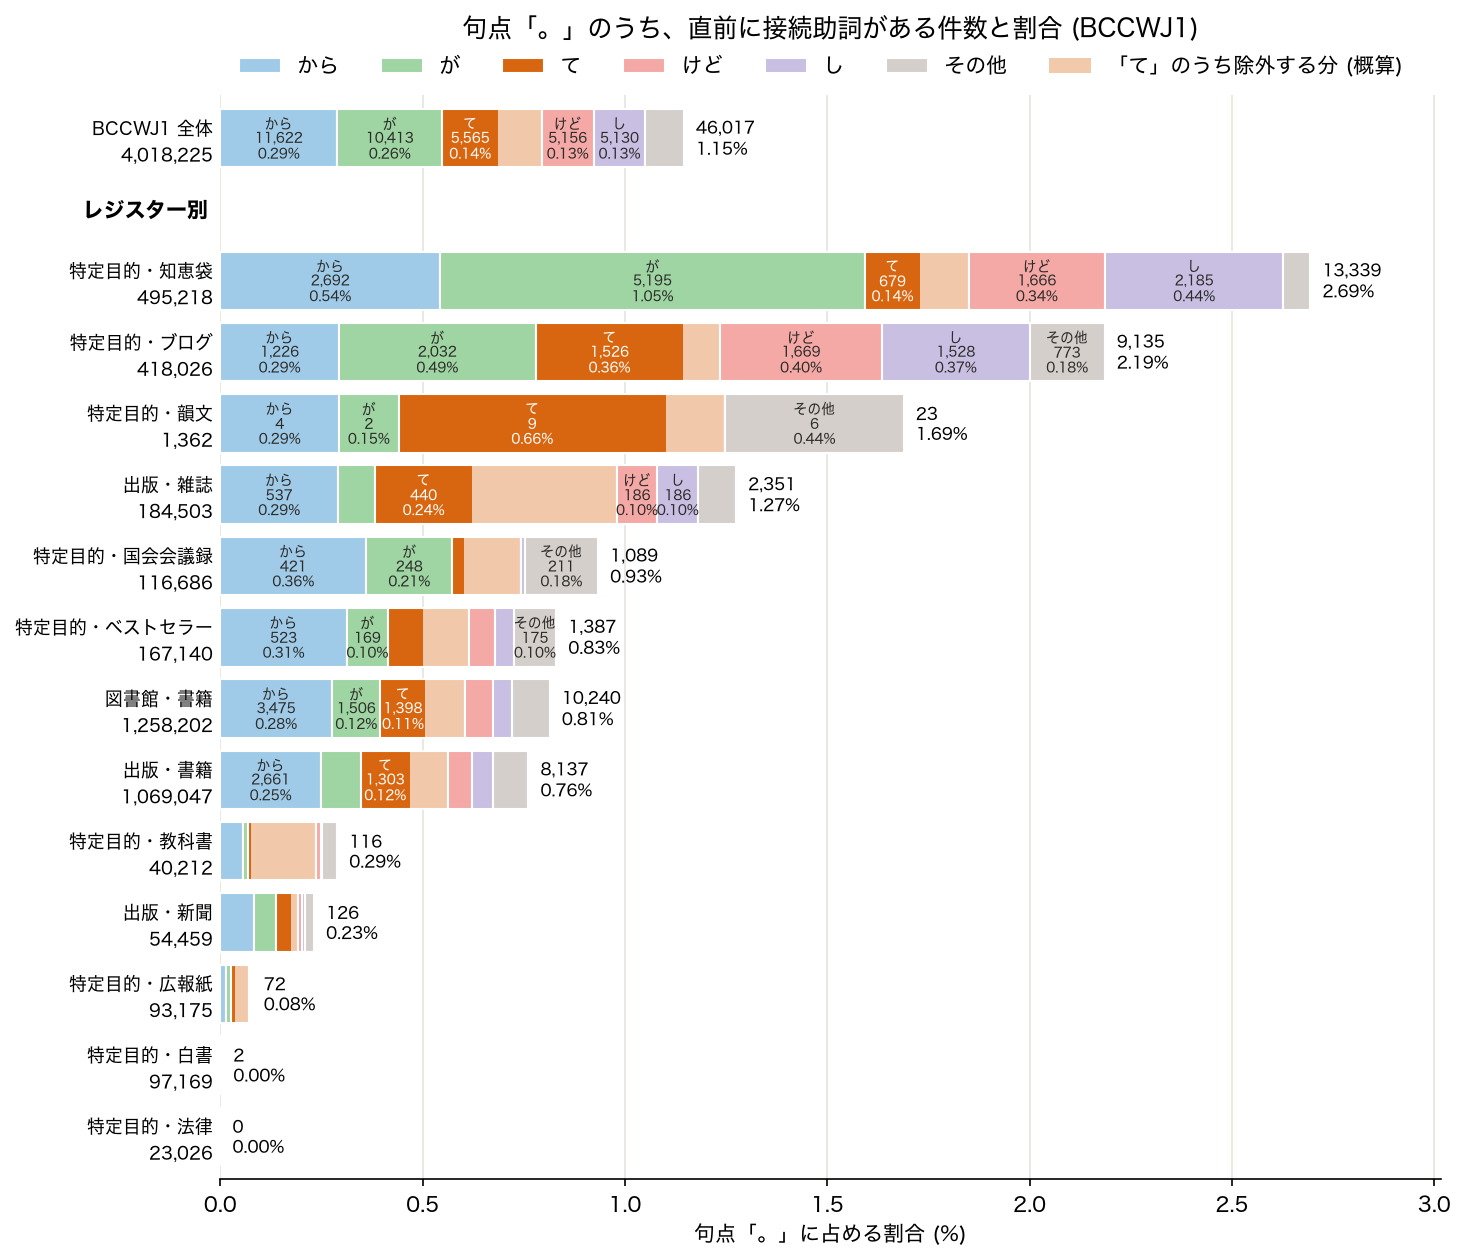

In [244]:
# 「て」の帯のうち、除外する分 (目安) を薄くして描く
te_rest = (estimate["残る割合 (%)"] / 100).rename({"全体": "BCCWJ1 全体"})
draw_register_chart(te_rest, save_path="figs/20261007_te_register_rest.png")

## 5. ノート

**元記事**「一体どこ発祥なのか」

- 2005 年の知恵袋、2008 年のブログにもうある（BCCWJ の知恵袋は 2005 年、ブログは 2008 年だけ）
- 「て。」が何文も続くことが特徴的なのかどうか、わからない（何文も続く用例はある）

**従属節のみを述べ主節を省略する**（増岡・田窪『基礎日本語文法』）

> 従属節だけを述べれば、結論が推測できる場合、主節を省略することができる。自分が結論を出すより、相手に出させるほうが丁寧になる場合、結論を曖昧にしたい場合、結論部分が慣用的に決まっている場合、等に使われる。  
> (18) 田中ですけど（山田君いますか）。  
> (19) 私はここにいますから（用があったら呼んでください）。  
> (20) あなたも行けば（どうですか）。  
> (21) きみも行けばいいのに（なぜ行かないの）。  
> (22) 行かなくては（いけない）。  
(p.177)

**テ形 副詞節**  
原因、条件、手段、付帯状況、等（増岡・田窪『基礎日本語文法』）

### 5.1. ほかにも
- 言いさし
